Imaginea originala

[[0 0 0 0 0]
 [0 1 1 1 0]
 [0 1 1 1 0]
 [0 1 1 1 0]
 [0 0 0 0 0]]


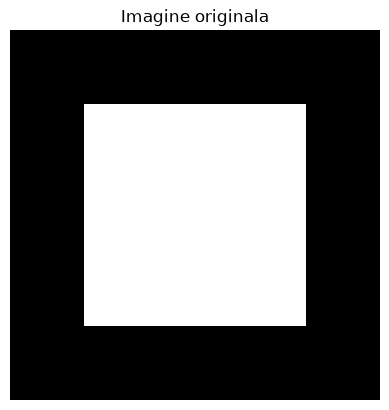

In [1]:
import numpy as np
import matplotlib.pyplot as plt

original = np.array([
    [0, 0, 0, 0, 0],
    [0, 1, 1, 1, 0],
    [0, 1, 1, 1, 0],
    [0, 1, 1, 1, 0],
    [0, 0, 0, 0, 0]
])

print(original)

plt.imshow(original, cmap="gray", vmin=0, vmax=1)
plt.title("Imagine originala")
plt.axis("off")
plt.show()

Pixeli modificati: [ 3 15]
[[0 0 0 1 0]
 [0 1 1 1 0]
 [0 1 1 1 0]
 [1 1 1 1 0]
 [0 0 0 0 0]]


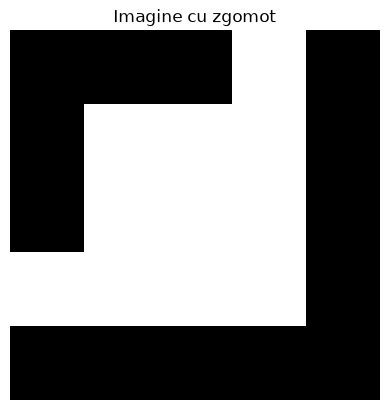

In [2]:
np.random.seed(16)

y = original.copy()

pozitii = np.random.choice(25, size=2, replace=False)

for poz in pozitii:
    i = poz // 5
    j = poz % 5
    y[i, j] = 1 - y[i, j]

print("Pixeli modificati:", pozitii)
print(y)

plt.imshow(y, cmap="gray", vmin=0, vmax=1)
plt.title("Imagine cu zgomot")
plt.axis("off")
plt.show()

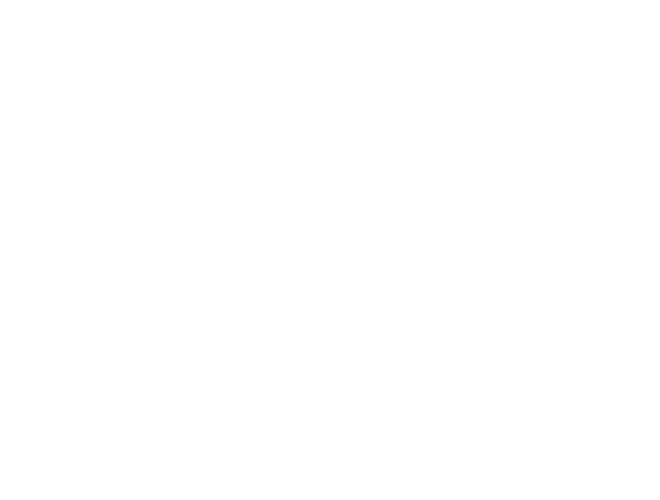

In [4]:
from pgmpy.models import DiscreteMarkovNetwork
import networkx as nx

mrf = DiscreteMarkovNetwork()

for i in range(5):
    for j in range(5):

        nod = f"X{i}_{j}"

        if i < 4:
            mrf.add_edge(nod, f"X{i+1}_{j}")

        if j < 4:
            mrf.add_edge(nod, f"X{i}_{j+1}")

nx.draw(
    mrf,
    with_labels=True,
    node_size=800,
    font_size=7
)

plt.show()

In [5]:
from pgmpy.factors.discrete import DiscreteFactor
import math

def construieste_model(y, lmbda):

    model = DiscreteMarkovNetwork()

    for i in range(5):
        for j in range(5):

            nod = f"X{i}_{j}"

            if i < 4:
                model.add_edge(nod, f"X{i+1}_{j}")

            if j < 4:
                model.add_edge(nod, f"X{i}_{j+1}")

    # factori unari
    for i in range(5):
        for j in range(5):

            nod = f"X{i}_{j}"

            valori = [
                math.exp(-lmbda * (0 - y[i, j])**2),
                math.exp(-lmbda * (1 - y[i, j])**2)
            ]

            factor = DiscreteFactor(
                [nod],
                [2],
                valori
            )

            model.add_factors(factor)

    # factori pereche
    for u, v in model.edges():

        valori = [
            [1, math.exp(-1)],
            [math.exp(-1), 1]
        ]

        factor = DiscreteFactor(
            [u, v],
            [2, 2],
            np.array(valori).flatten()
        )

        model.add_factors(factor)

    return model

In [6]:
def vecini(i, j):
    rezultat = []

    if i > 0:
        rezultat.append((i - 1, j))

    if i < 4:
        rezultat.append((i + 1, j))

    if j > 0:
        rezultat.append((i, j - 1))

    if j < 4:
        rezultat.append((i, j + 1))

    return rezultat


def icm(y, lmbda):
    x = y.copy()

    while True:

        modificat = False

        for i in range(5):
            for j in range(5):

                energii = []

                for valoare in [0, 1]:

                    energie = lmbda * (valoare - y[i, j])**2

                    for vi, vj in vecini(i, j):
                        energie += (valoare - x[vi, vj])**2

                    energii.append(energie)

                valoare_noua = np.argmin(energii)

                if valoare_noua != x[i, j]:
                    x[i, j] = valoare_noua
                    modificat = True

        if not modificat:
            break

    return x

lambda = 0.3
[[1 1 1 1 0]
 [1 1 1 1 0]
 [1 1 1 1 0]
 [1 1 1 1 0]
 [0 0 0 0 0]]
Pixeli gresiti: 7


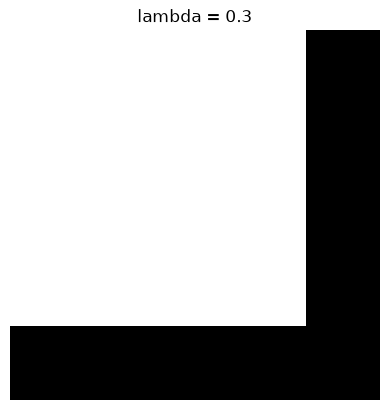

lambda = 1
[[0 0 0 0 0]
 [0 1 1 1 0]
 [0 1 1 1 0]
 [0 1 1 1 0]
 [0 0 0 0 0]]
Pixeli gresiti: 0


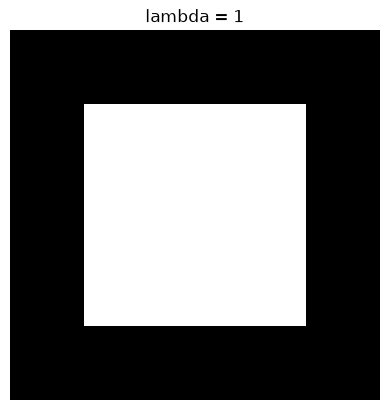

lambda = 3
[[0 0 0 1 0]
 [0 1 1 1 0]
 [0 1 1 1 0]
 [1 1 1 1 0]
 [0 0 0 0 0]]
Pixeli gresiti: 2


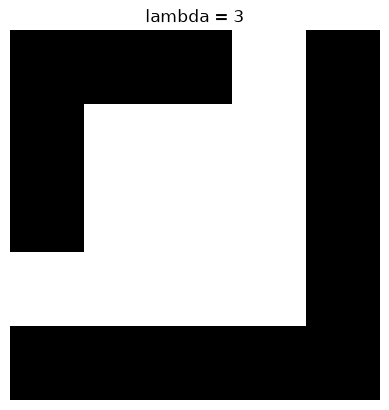

In [7]:
lambdas = [0.3, 1, 3]

for lmbda in lambdas:

    model = construieste_model(y, lmbda)

    restaurata = icm(y, lmbda)

    greseli = np.sum(restaurata != original)

    print("lambda =", lmbda)
    print(restaurata)
    print("Pixeli gresiti:", greseli)

    plt.imshow(restaurata, cmap="gray", vmin=0, vmax=1)
    plt.title(f"lambda = {lmbda}")
    plt.axis("off")
    plt.show()